# Notebook 3 — ตัวตรวจอุปกรณ์ปลอม (YOLO26n) + fine-tune anti-spoof

**เป้าหมาย:** ลดการปฏิเสธคนจริง และจับมือถือ/แท็บเล็ต/รูปพิมพ์ ได้กับกล้องทุกแบบ โดยไม่ต้องเก็บข้อมูลเองในห้อง

| ชั้น | โมเดล | ข้อมูล | จับอะไร |
|---|---|---|---|
| หาหน้า | YOLO26s (notebook 1, **เทรนเอง**) | WIDER FACE | ทุกหน้าในภาพ |
| **ตรวจอุปกรณ์** | **YOLO26n (notebook นี้, เทรนเอง)** | Roboflow *face-anti-spoofing-detection* (CC BY 4.0) | หน้าอยู่ในกรอบ `fake` (มือถือ/จอ/รูปพิมพ์ที่เห็นขอบ) |
| ดูเนื้อภาพ | ConvNeXt (notebook 2) + **fine-tune ในนี้** | CelebA-Spoof + Roboflow + Axon | ยื่นจอชิดกล้องจนไม่เห็นขอบ |

ตัดสิน: **ปลอม = (หน้าอยู่ในกรอบ fake ≥ `DEV_CONF`) หรือ (P(spoof) ≥ `AS_THR`)** — notebook จะเลือกค่าทั้งสองให้เอง

**ต้องมีก่อนรัน**
1. Runtime → GPU (T4 พอ)
2. Colab **Secrets** (รูปกุญแจซ้ายมือ): `ROBOFLOW_API_KEY`, `KAGGLE_USER`, `KAGGLE_KEY` — **ห้ามวาง key ลงในโค้ด**
3. ใน Drive (มีอยู่แล้วจาก notebook 1–2):
   - `roll_call/yolo_face/yolo26s_widerface_960/export/yolo26s_widerface_960_best.pt`
   - `roll_call/antispoof/export/antispoof_convnext_aug_ema.pt` + `antispoof_config.json`
   - (ถ้ายังอยู่) `roll_call/antispoof/cache/celeba_n40000_s1.5_keep5.zip/.csv` → ใช้กันโมเดลลืมของเดิมตอน fine-tune
4. (แนะนำ) อัปโหลดโฟลเดอร์ `image_pyiot\test set` ไปที่ `roll_call/test_set/` — รูปคนจริงจากกล้องหลายแบบ
   ถ้ามีรูปปลอมที่ถ่ายเอง (ถ่ายจอ/รูปพิมพ์) ใส่ใน `roll_call/test_set/spoof/`

**ชุดทดสอบที่ไม่รั่ว (ใช้ตัดสินจริง):** Axon โฟลเดอร์ `AXON_HOLDOUT` (อุปกรณ์ที่ไม่เคยเห็นตอนเทรน) + `test_set` ของเรา + CelebA val
`rf_test` ของ Roboflow อาจมีเฟรมจากคลิปเดียวกับ train → ตัวเลขดูดีเกินจริง ใช้ดูประกอบเท่านั้น

รันได้ทั้งหมดด้วย *Run all* — ถ้าหลุดกลางทาง รันใหม่ได้ ส่วนที่เสร็จแล้วจะข้าม (เก็บไว้ใน Drive)

## 0. ติดตั้ง / ตั้งค่า

In [4]:
!pip install -q -U ultralytics roboflow timm albumentations onnx onnxslim onnxruntime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 87.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 149.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.8/245.8 kB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 106.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 117.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.7 MB/s eta 0:00:00


In [7]:
import os, json, time, math, random, shutil, copy
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import timm
import albumentations as A
from sklearn.metrics import roc_auc_score, roc_curve

from google.colab import drive, userdata
drive.mount("/content/drive")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = os.cpu_count() or 2
print(f"torch {torch.__version__} | timm {timm.__version__} | albumentations {A.__version__}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> Runtime > Change runtime type > GPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.11.0+cu130 | timm 1.0.30 | albumentations 2.0.8
GPU: NVIDIA L4


In [8]:
# ---- Paths (Drive) ----
ROOT = Path("/content/drive/MyDrive/roll_call")
FACE_YOLO = ROOT / "yolo_face/yolo26s_widerface_960/export/yolo26s_widerface_960_best.pt"
ANTISPOOF_PT = ROOT / "antispoof/export/antispoof_convnext_aug_ema.pt"
ANTISPOOF_CFG = ROOT / "antispoof/export/antispoof_config.json"
CELEBA_CACHE = ROOT / "antispoof/cache/celeba_n40000_s1.5_keep5"   # .zip + .csv from notebook 2 (optional)
OUR_TEST_DIR = ROOT / "test_set"                                   # optional: class photos (live) + spoof/ sub-folder
OUT_DIR = ROOT / "spoof_yolo"                                      # everything from this notebook
DATA_DIR = Path("/content/datasets")                               # local disk (fast)
CROPS = Path("/content/crops3")

# ---- Datasets ----
RF_WORKSPACE, RF_PROJECT, RF_VERSION = "weijers-workspace", "face-anti-spoofing-detection-w9knd", 1
AXON_SLUG = "axondata/replay-attack-mobile-dataset-ibeta-1"
AXON_HOLDOUT = "Galaxy_a54-Honor70"   # this device pair is NEVER trained on -> unseen-device test
AXON_FPS = 3                          # frames kept per second of video

# ---- Device detector (YOLO) ----
DET_MODEL = "yolo26n.pt"
DET_IMGSZ = 640
DET_EPOCHS = 80
DET_BATCH = 32
DET_PATIENCE = 15
IOA_MIN = 0.6         # face counts as "inside" a fake box when >= 60% of the face area is inside it

# ---- Face crop (must match the app) ----
FACE_IMGSZ = 640
FACE_CONF = 0.35
CROP_SCALE = 1.5
IMG_SIZE = 224
MIN_FACE_PX = 40

# ---- Anti-spoof fine-tune ----
FT_EPOCHS = 5
FT_LR = 3e-5          # small: adapt, do not forget CelebA-Spoof
FT_BATCH = 64
CELEBA_MIX = 8000     # CelebA-Spoof crops mixed into fine-tune data (0 = none)
SEED = 42

for d in (OUT_DIR, DATA_DIR, CROPS):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert FACE_YOLO.exists(), f"not found: {FACE_YOLO}"
assert ANTISPOOF_PT.exists(), f"not found: {ANTISPOOF_PT}"

AS_CFG = json.load(open(ANTISPOOF_CFG))
OLD_THRESHOLD = AS_CFG["threshold"]
MEAN = np.array(AS_CFG["normalize"]["mean"], np.float32)
STD = np.array(AS_CFG["normalize"]["std"], np.float32)
print("old anti-spoof threshold:", round(OLD_THRESHOLD, 4))
print("CelebA cache:", "found" if Path(str(CELEBA_CACHE) + ".csv").exists() else "not found (fine-tune without it)")
print("our test set:", "found" if OUR_TEST_DIR.exists() else "not found (skip)")

old anti-spoof threshold: 0.1977
CelebA cache: found
our test set: not found (skip)


## 1. ข้อมูล
### 1.1 Roboflow (กรอบ fake / real)

In [10]:
RF_DIR = DATA_DIR / "rf"
if not (RF_DIR / "data.yaml").exists():
    from roboflow import Roboflow
    rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
    rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download("yolov8", location=str(RF_DIR))

RF_NAMES = yaml.safe_load(open(RF_DIR / "data.yaml"))["names"]
FAKE_ID, REAL_ID = RF_NAMES.index("fake"), RF_NAMES.index("real")
# absolute paths (Roboflow's ../train/images confuses ultralytics)
DATA_YAML = RF_DIR / "data_abs.yaml"
yaml.safe_dump({"path": str(RF_DIR), "train": "train/images", "val": "valid/images", "test": "test/images",
                "names": dict(enumerate(RF_NAMES))}, open(DATA_YAML, "w"), allow_unicode=True)

def gt_boxes(img_path, w, h):
    # YOLO txt -> [(cls, x1, y1, x2, y2)] in pixels
    lbl = Path(img_path).parent.parent / "labels" / (Path(img_path).stem + ".txt")
    out = []
    if lbl.exists():
        for line in open(lbl):
            v = line.split()
            if len(v) >= 5:
                c, x, y, bw, bh = int(v[0]), *map(float, v[1:5])
                out.append((c, (x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h))
    return out

def rf_images(split):
    return sorted((RF_DIR / split / "images").glob("*.*"))

rows = []
for split in ("train", "valid", "test"):
    for p in rf_images(split):
        boxes = gt_boxes(p, 1, 1)
        rows.append({"split": split, "fake": sum(b[0] == FAKE_ID for b in boxes), "real": sum(b[0] == REAL_ID for b in boxes),
                     "fake_area": max([(b[3] - b[1]) * (b[4] - b[2]) for b in boxes if b[0] == FAKE_ID], default=np.nan)})
RF_STATS = pd.DataFrame(rows)
display(RF_STATS.groupby("split").agg(images=("fake", "size"), fake_boxes=("fake", "sum"), real_boxes=("real", "sum"),
                                       no_box_images=("fake", lambda s: int(((s == 0) & (RF_STATS.loc[s.index, "real"] == 0)).sum())),
                                       median_fake_area=("fake_area", "median")))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/rf in yolov8:: 100%|██████████| 12263/12263 [00:01<00:00, 9382.28it/s] 


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,images,fake_boxes,real_boxes,no_box_images,median_fake_area
split,,,,,
test,920,646,347,18,0.320654
train,4290,2944,1696,95,0.328586
valid,919,638,361,15,0.311992


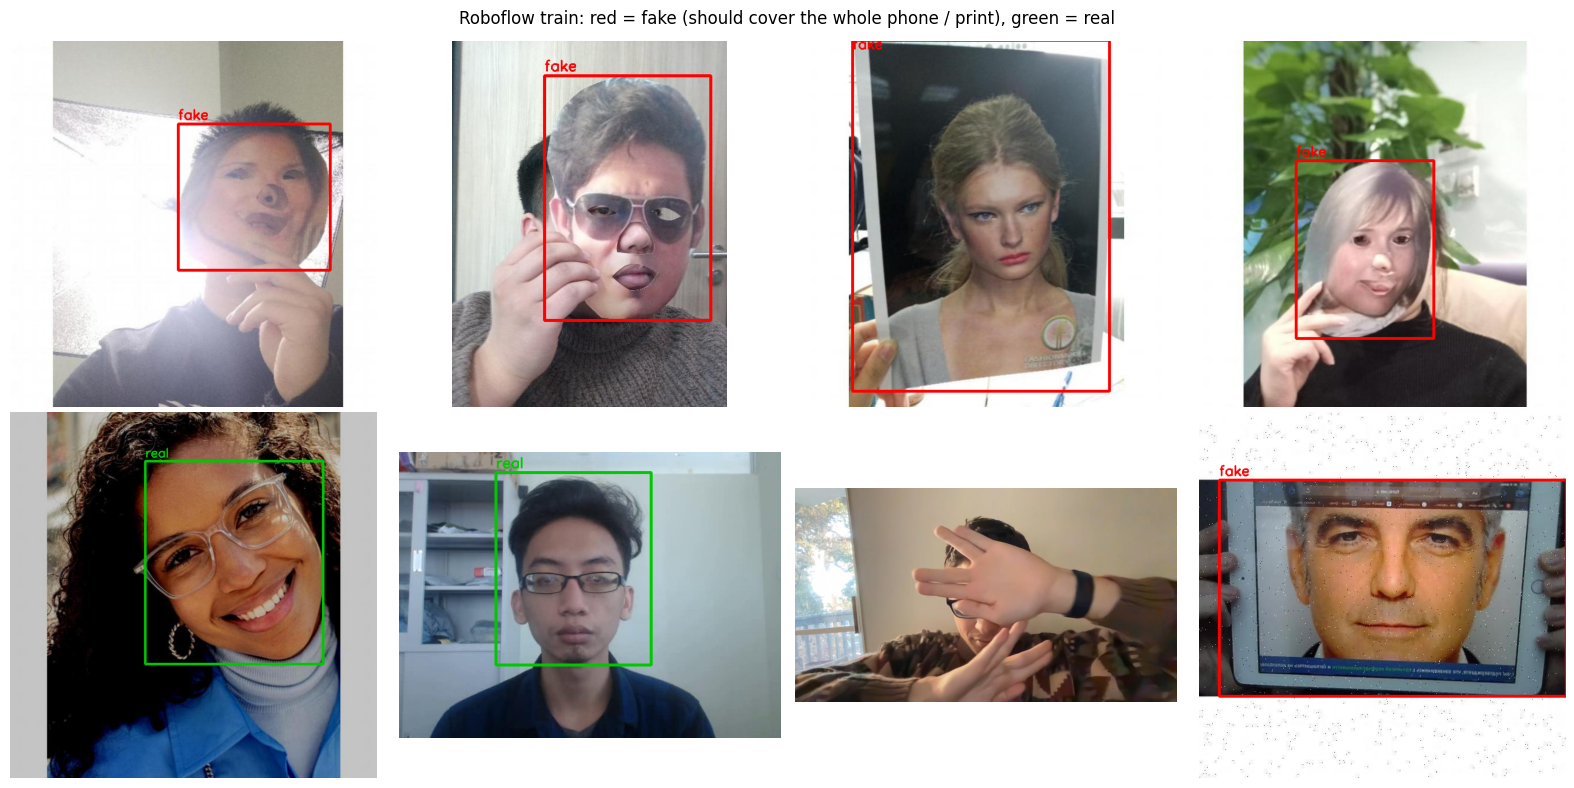

In [11]:
def show_rf(paths, title=""):
    plt.figure(figsize=(16, 8))
    for i, p in enumerate(paths[:8]):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        for c, x1, y1, x2, y2 in gt_boxes(p, w, h):
            color = (255, 0, 0) if c == FAKE_ID else (0, 200, 0)
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
            cv2.putText(img, RF_NAMES[c], (int(x1), max(int(y1) - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
        plt.subplot(2, 4, i + 1); plt.imshow(img); plt.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

random.seed(1)
show_rf(random.sample(rf_images("train"), 8), "Roboflow train: red = fake (should cover the whole phone / print), green = real")

### 1.2 Axon replay (ตัวอย่างฟรี 39 คลิป, ภาพปลอมแบบไม่เห็นขอบเครื่อง)

In [12]:
AXON_DIR, AXON_FRAMES = DATA_DIR / "axon", DATA_DIR / "axon_frames"
if not any(AXON_DIR.rglob("*.mp4")):
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USER")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    !kaggle datasets download -d {AXON_SLUG} -p {AXON_DIR} --unzip -q

rows = []
for video in tqdm(sorted(AXON_DIR.rglob("*.mp4")), desc="frames"):
    folder = video.parent.name
    out = AXON_FRAMES / folder
    out.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(str(video))
    step = max(1, round((cap.get(cv2.CAP_PROP_FPS) or 30) / AXON_FPS))
    i = k = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % step == 0:
            p = out / f"{video.stem}_{k:03d}.jpg"
            if not p.exists():
                s = 1280 / max(frame.shape[:2])
                if s < 1:
                    frame = cv2.resize(frame, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
                cv2.imwrite(str(p), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
            rows.append({"path": str(p), "folder": folder, "video": video.stem})
            k += 1
        i += 1
    cap.release()
AXON_DF = pd.DataFrame(rows)
display(AXON_DF.groupby("folder").agg(videos=("video", "nunique"), frames=("path", "size")))
assert AXON_HOLDOUT in set(AXON_DF.folder), f"AXON_HOLDOUT must be one of {sorted(AXON_DF.folder.unique())}"

Dataset URL: https://www.kaggle.com/datasets/axondata/replay-attack-mobile-dataset-ibeta-1
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)


frames:   0%|          | 0/39 [00:00<?, ?it/s]

,videos,frames
folder,,
Galaxy_a54-Honor70,10,351
Galaxy_a54-Pixel7,10,343
Honor70-pixel7,9,303
Pixel7-Honor70,10,336


### 1.3 ครอปหน้าด้วย YOLO26s ตัวเก่า (เหมือนในแอป)

In [13]:
from ultralytics import YOLO
face_yolo = YOLO(str(FACE_YOLO))

def square_box(x1, y1, x2, y2, img_w, img_h, scale=CROP_SCALE):
    # same as the app / notebook 2
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = min(max(x2 - x1, y2 - y1) * scale, img_w, img_h)
    left = min(max(cx - side / 2, 0), img_w - side)
    top = min(max(cy - side / 2, 0), img_h - side)
    return int(left), int(top), int(left + side), int(top + side)

def ioa(face, box):
    # intersection / face area
    ix = max(0, min(face[2], box[2]) - max(face[0], box[0]))
    iy = max(0, min(face[3], box[3]) - max(face[1], box[1]))
    area = max((face[2] - face[0]) * (face[3] - face[1]), 1e-6)
    return ix * iy / area

def build_faces(paths, name, label_fn, largest_only=False, extra=None, batch=32):
    # detect faces, save 224 crops, label each face with label_fn(path, w, h, face_box) -> 0 / 1 / None (skip)
    out_dir = CROPS / name
    out_dir.mkdir(parents=True, exist_ok=True)
    rows, missed = [], 0
    for start in tqdm(range(0, len(paths), batch), desc=name):
        chunk = [str(p) for p in paths[start:start + batch]]
        results = face_yolo.predict(chunk, imgsz=FACE_IMGSZ, conf=FACE_CONF, verbose=False)
        for path, res in zip(chunk, results):
            img = cv2.imread(path)
            h, w = img.shape[:2]
            faces = [b for b in res.boxes.xyxy.cpu().numpy().tolist() if max(b[2] - b[0], b[3] - b[1]) >= MIN_FACE_PX]
            if largest_only and faces:
                faces = [max(faces, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))]
            if not faces:
                missed += 1
            for j, box in enumerate(faces):
                label = label_fn(path, w, h, box)
                if label is None:
                    continue
                x1, y1, x2, y2 = square_box(*box, w, h)
                crop = cv2.resize(img[y1:y2, x1:x2], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
                crop_path = out_dir / f"{len(rows):06d}.jpg"
                cv2.imwrite(str(crop_path), crop, [cv2.IMWRITE_JPEG_QUALITY, 95])
                row = {"crop": str(crop_path), "image": path, "box": [round(v, 1) for v in box],
                       "size": int(max(box[2] - box[0], box[3] - box[1])), "label": int(label)}
                if extra:
                    row.update(extra(path))
                rows.append(row)
    df = pd.DataFrame(rows)
    print(f"{name}: {len(df)} faces (live {(df.label == 0).sum() if len(df) else 0}, "
          f"spoof {(df.label == 1).sum() if len(df) else 0}) | images without a face: {missed}/{len(paths)}")
    return df

def rf_label(path, w, h, face):
    # face inside a fake box -> spoof, inside a real box -> live, otherwise skip
    boxes = gt_boxes(path, w, h)
    fake = max([ioa(face, b[1:]) for b in boxes if b[0] == FAKE_ID], default=0)
    real = max([ioa(face, b[1:]) for b in boxes if b[0] == REAL_ID], default=0)
    if fake >= 0.5 and fake >= real:
        return 1
    if real >= 0.5:
        return 0
    return None

FACES_PKL = CROPS / "faces.pkl"
if FACES_PKL.exists():
    FACES = pd.read_pickle(FACES_PKL)
else:
    FACES = {s: build_faces(rf_images(s), f"rf_{s}", rf_label) for s in ("train", "valid", "test")}
    FACES = {"rf_train": FACES["train"], "rf_valid": FACES["valid"], "rf_test": FACES["test"]}
    folder_of = dict(zip(AXON_DF.path, AXON_DF.folder))
    FACES["axon"] = build_faces(AXON_DF.path.tolist(), "axon", lambda *a: 1, largest_only=True,
                                extra=lambda p: {"folder": folder_of[p]})
    our = []
    if OUR_TEST_DIR.exists():
        our = [p for p in sorted(OUR_TEST_DIR.rglob("*")) if p.suffix.lower() in (".jpg", ".jpeg", ".png")
               and not p.stem.startswith("labels_")]
    FACES["our"] = (build_faces(our, "our", lambda p, *a: 1 if "spoof" in Path(p).parts[-2].lower() else 0)
                    if our else pd.DataFrame(columns=["crop", "image", "box", "size", "label"]))
    pd.to_pickle(FACES, FACES_PKL)

EVAL_SETS = {
    "rf_test (may leak)": FACES["rf_test"],
    "axon_holdout (unseen device)": FACES["axon"][FACES["axon"].folder == AXON_HOLDOUT].reset_index(drop=True),
    "our_test (class photos)": FACES["our"],
}
EVAL_SETS = {k: v for k, v in EVAL_SETS.items() if len(v)}
for k, v in EVAL_SETS.items():
    print(f"{k:30s} live {(v.label == 0).sum():5d} | spoof {(v.label == 1).sum():5d}")

rf_train:   0%|          | 0/135 [00:00<?, ?it/s]

rf_train: 4427 faces (live 1641, spoof 2786) | images without a face: 272/4290


rf_valid:   0%|          | 0/29 [00:00<?, ?it/s]

rf_valid: 976 faces (live 357, spoof 619) | images without a face: 37/919


rf_test:   0%|          | 0/29 [00:00<?, ?it/s]

rf_test: 946 faces (live 338, spoof 608) | images without a face: 55/920


axon:   0%|          | 0/42 [00:00<?, ?it/s]

axon: 1333 faces (live 0, spoof 1333) | images without a face: 0/1333
rf_test (may leak)             live   338 | spoof   608
axon_holdout (unseen device)   live     0 | spoof   351


## 2. Baseline: anti-spoof ตัวเก่าทำได้แค่ไหน (ก่อนเพิ่มอะไร)

In [14]:
EVAL_TF = A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_AREA)

class CropDS(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), np.asarray(labels, int), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        img = self.transform(image=img)["image"].astype(np.float32) / 255.0
        img = (img - MEAN) / STD
        return torch.from_numpy(img.transpose(2, 0, 1).copy()), self.labels[i]

def load_antispoof(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model = timm.create_model(ckpt["backbone"], pretrained=False, num_classes=2)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(DEVICE).eval(), ckpt["backbone"]

@torch.no_grad()
def spoof_scores(model, df):
    if len(df) == 0:
        return np.zeros(0)
    model.eval()
    loader = DataLoader(CropDS(df.crop, df.label, EVAL_TF), batch_size=128, num_workers=NUM_WORKERS)
    out = []
    for x, _ in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(x.to(DEVICE)).float().softmax(1)[:, 1].cpu())
    return torch.cat(out).numpy()

def safe_div(a, b):
    return a / b if b else float("nan")

def metrics(y, pred, score=None):
    # spoof = positive class
    y, pred = np.asarray(y, int), np.asarray(pred, int)
    tp, fn = int(((pred == 1) & (y == 1)).sum()), int(((pred == 0) & (y == 1)).sum())
    fp, tn = int(((pred == 1) & (y == 0)).sum()), int(((pred == 0) & (y == 0)).sum())
    apcer, bpcer = safe_div(fn, tp + fn), safe_div(fp, fp + tn)
    f1s, f1l = safe_div(2 * tp, 2 * tp + fp + fn), safe_div(2 * tn, 2 * tn + fn + fp)
    auc = roc_auc_score(y, score) if score is not None and 0 < y.sum() < len(y) else float("nan")
    return {"n_live": fp + tn, "n_spoof": tp + fn, "APCER": apcer, "BPCER": bpcer,
            "ACER": np.nanmean([apcer, bpcer]), "Precision": safe_div(tp, tp + fp), "Recall": safe_div(tp, tp + fn),
            "F1_spoof": f1s, "F1_live": f1l, "F1_macro": np.nanmean([f1s, f1l]), "AUC": auc}

def eer_threshold(y, s):
    fpr, tpr, thr = roc_curve(y, s)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return float(min(thr[i], 1.0)), float((fpr[i] + 1 - tpr[i]) / 2)

OLD_AS, BACKBONE = load_antispoof(ANTISPOOF_PT)
OLD_SCORES = {k: spoof_scores(OLD_AS, v) for k, v in EVAL_SETS.items()}

rows = []
for thr in (OLD_THRESHOLD, 0.5, 0.9):
    for k, v in EVAL_SETS.items():
        rows.append({"threshold": round(thr, 3), "set": k, **metrics(v.label, OLD_SCORES[k] >= thr, OLD_SCORES[k])})
BASELINE = pd.DataFrame(rows)
display(BASELINE.round(3))
print("APCER = spoof accepted as live | BPCER = live rejected | n/a (nan) = that class is not in the set")

,threshold,set,n_live,n_spoof,APCER,BPCER,ACER,Precision,Recall,F1_spoof,F1_live,F1_macro,AUC
0,0.198,rf_test (may leak),338,608,0.105,0.160,0.133,0.910,0.895,0.902,0.828,0.865,0.905
1,0.198,axon_holdout (unseen device),0,351,0.063,NaN,0.063,1.000,0.937,0.968,0.000,0.484,NaN
2,0.500,rf_test (may leak),338,608,0.133,0.124,0.129,0.926,0.867,0.895,0.828,0.862,0.905
3,0.500,axon_holdout (unseen device),0,351,0.148,NaN,0.148,1.000,0.852,0.920,0.000,0.460,NaN
4,0.900,rf_test (may leak),338,608,0.192,0.092,0.142,0.941,0.808,0.869,0.806,0.837,0.905
5,0.900,axon_holdout (unseen device),0,351,0.385,NaN,0.385,1.000,0.615,0.762,0.000,0.381,NaN


APCER = spoof accepted as live | BPCER = live rejected | n/a (nan) = that class is not in the set


## 3. เทรน YOLO26n ตรวจอุปกรณ์ปลอม (Roboflow)

In [15]:
try:
    YOLO(DET_MODEL)
except Exception as e:
    print(f"!! {DET_MODEL} not available ({e}) -> fallback yolo11n.pt")
    DET_MODEL = "yolo11n.pt"

RUN_NAME = f"{Path(DET_MODEL).stem}_spoof_{DET_IMGSZ}"
RUN_DIR = OUT_DIR / "runs" / RUN_NAME
BEST_PT, LAST_PT, DONE = RUN_DIR / "weights/best.pt", RUN_DIR / "weights/last.pt", RUN_DIR / "done.json"

if DONE.exists():
    print("already trained -> skip:", RUN_DIR)
else:
    try:
        if LAST_PT.exists():
            print("resume:", LAST_PT)
            YOLO(str(LAST_PT)).train(resume=True)
        else:
            YOLO(DET_MODEL).train(data=str(DATA_YAML), epochs=DET_EPOCHS, imgsz=DET_IMGSZ, batch=DET_BATCH,
                                  patience=DET_PATIENCE, project=str(OUT_DIR / "runs"), name=RUN_NAME, exist_ok=True,
                                  seed=SEED, workers=NUM_WORKERS, plots=True)
    except AssertionError as e:      # "nothing to resume" = training had already finished
        print("note:", e)
    DONE.write_text(json.dumps({"finished": time.ctime(), "model": DET_MODEL}))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/rf/data_abs.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_spoof_640, nbs=64, nms=None, opset=None, optimi

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1599.4±393.9 MB/s, size: 65.0 KB)
val: Scanning /content/datasets/rf/test/labels... 920 images, 18 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 920/920 1.5Kit/s 0.6s
val: New cache created: /content/datasets/rf/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 5.5it/s 5.3s
                   all        920        993      0.971      0.981      0.981      0.873
Speed: 0.7ms preprocess, 2.4ms inference, 0.0ms loss, 0.8ms postprocess per image
Roboflow test (may leak): {'mAP50': 0.981, 'mAP50_95': 0.873, 'mAP50_95_fake': 0.971, 'mAP50_95_real': 0.776}


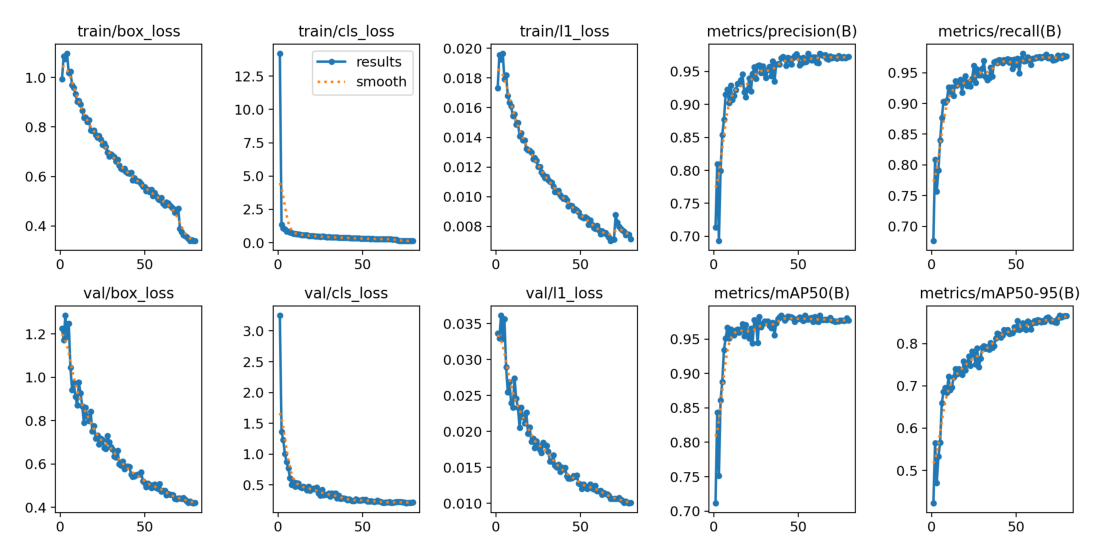

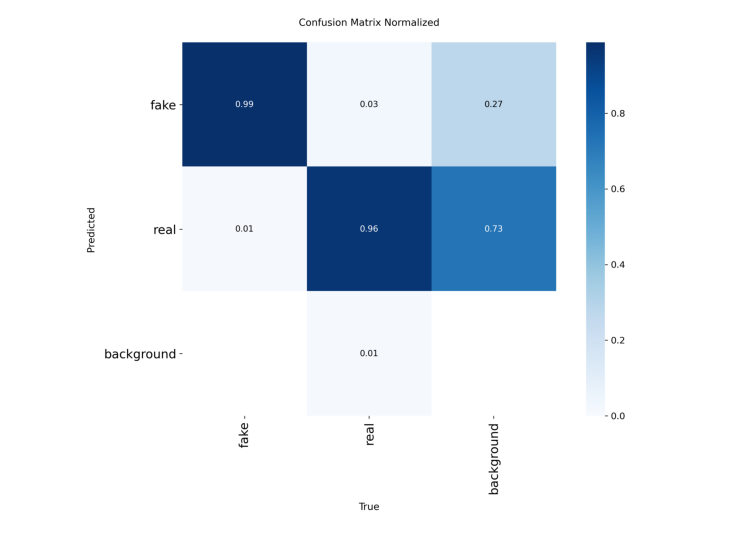

In [16]:
DET = YOLO(str(BEST_PT))
m = DET.val(data=str(DATA_YAML), split="test", imgsz=DET_IMGSZ, batch=DET_BATCH, plots=False, verbose=False)
DET_TEST = {"mAP50": float(m.box.map50), "mAP50_95": float(m.box.map),
            **{f"mAP50_95_{n}": float(v) for n, v in zip(RF_NAMES, m.box.maps)}}
print("Roboflow test (may leak):", {k: round(v, 3) for k, v in DET_TEST.items()})
for f in ("results.png", "confusion_matrix_normalized.png"):
    if (RUN_DIR / f).exists():
        plt.figure(figsize=(14, 7)); plt.imshow(plt.imread(RUN_DIR / f)); plt.axis("off"); plt.show()

In [17]:
@torch.no_grad()
def device_scores(df, conf_min=0.05, batch=32):
    # per face: highest confidence of a "fake" box that contains >= IOA_MIN of the face
    out = np.zeros(len(df))
    if len(df) == 0:
        return out
    images = df.image.unique().tolist()
    fakes = {}
    for start in range(0, len(images), batch):
        chunk = images[start:start + batch]
        for path, res in zip(chunk, DET.predict(chunk, imgsz=DET_IMGSZ, conf=conf_min, verbose=False)):
            b = res.boxes
            fakes[path] = [(box, c) for box, c, k in zip(b.xyxy.cpu().numpy().tolist(), b.conf.cpu().numpy().tolist(),
                                                      b.cls.cpu().numpy().astype(int).tolist()) if k == FAKE_ID]
    for i, (path, face) in enumerate(zip(df.image, df.box)):
        out[i] = max([c for box, c in fakes[path] if ioa(face, box) >= IOA_MIN], default=0.0)
    return out

DEV_SCORES = {k: device_scores(v) for k, v in EVAL_SETS.items()}
rows = []
for conf in (0.25, 0.4, 0.5, 0.6, 0.75):
    for k, v in EVAL_SETS.items():
        rows.append({"dev_conf": conf, "set": k, **metrics(v.label, DEV_SCORES[k] >= conf, DEV_SCORES[k])})
display(pd.DataFrame(rows).round(3))
print("detector alone: axon_holdout APCER is expected to be high (no phone borders) -> that is the anti-spoof's job")

,dev_conf,set,n_live,n_spoof,APCER,BPCER,ACER,Precision,Recall,F1_spoof,F1_live,F1_macro,AUC
0,0.25,rf_test (may leak),338,608,0.012,0.006,0.009,0.997,0.988,0.993,0.987,0.990,0.996
1,0.25,axon_holdout (unseen device),0,351,0.319,NaN,0.319,1.000,0.681,0.810,0.000,0.405,NaN
2,0.40,rf_test (may leak),338,608,0.012,0.006,0.009,0.997,0.988,0.993,0.987,0.990,0.996
3,0.40,axon_holdout (unseen device),0,351,0.373,NaN,0.373,1.000,0.627,0.771,0.000,0.385,NaN
4,0.50,rf_test (may leak),338,608,0.015,0.006,0.010,0.997,0.985,0.991,0.984,0.987,0.996
5,0.50,axon_holdout (unseen device),0,351,0.419,NaN,0.419,1.000,0.581,0.735,0.000,0.368,NaN
6,0.60,rf_test (may leak),338,608,0.016,0.006,0.011,0.997,0.984,0.990,0.982,0.986,0.996
7,0.60,axon_holdout (unseen device),0,351,0.467,NaN,0.467,1.000,0.533,0.695,0.000,0.348,NaN
8,0.75,rf_test (may leak),338,608,0.021,0.006,0.014,0.997,0.979,0.988,0.978,0.983,0.996
9,0.75,axon_holdout (unseen device),0,351,0.556,NaN,0.556,1.000,0.444,0.615,0.000,0.308,NaN


detector alone: axon_holdout APCER is expected to be high (no phone borders) -> that is the anti-spoof's job


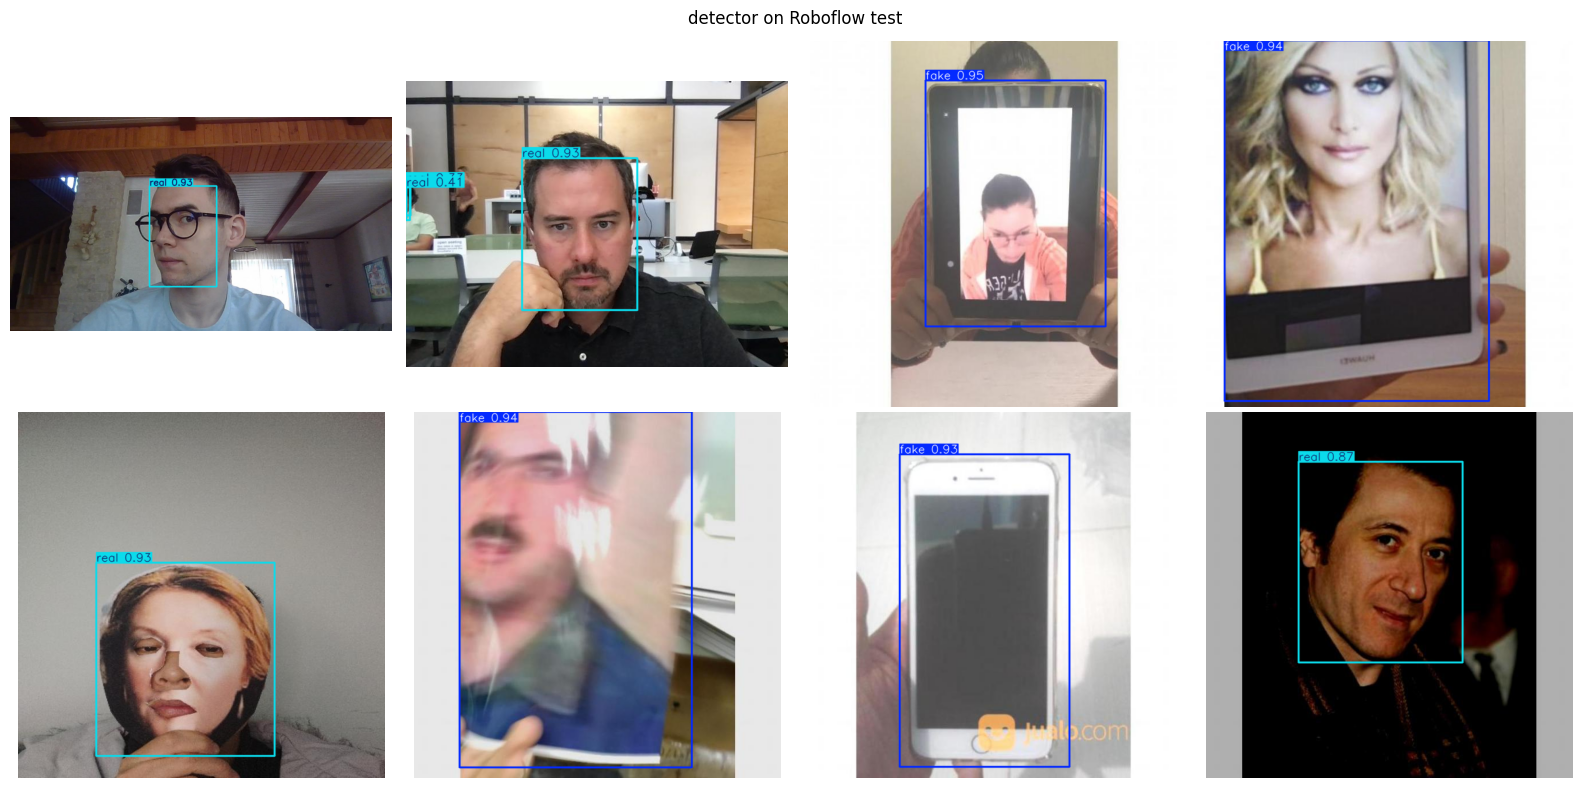

In [18]:
def show_detections(paths, title, n=8):
    paths = list(paths)[:n]
    if not paths:
        return
    plt.figure(figsize=(16, 8))
    for i, p in enumerate(paths):
        res = DET.predict(str(p), imgsz=DET_IMGSZ, conf=0.25, verbose=False)[0]
        plt.subplot(2, 4, i + 1); plt.imshow(res.plot()[:, :, ::-1]); plt.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

random.seed(2)
show_detections(random.sample(rf_images("test"), 8), "detector on Roboflow test")
if "our_test (class photos)" in EVAL_SETS:
    show_detections(EVAL_SETS["our_test (class photos)"].image.unique()[:8], "detector on OUR photos (live -> should show no 'fake')")

## 4. Fine-tune anti-spoof (ConvNeXt) — รับเฉพาะถ้าดีขึ้นบนชุดที่ไม่รั่ว

In [19]:
FT_DIR = OUT_DIR / "finetune"
FT_DIR.mkdir(parents=True, exist_ok=True)

# CelebA-Spoof crops from notebook 2 (keeps the old knowledge + guards against forgetting)
CELEBA_TRAIN = CELEBA_VAL = pd.DataFrame(columns=["crop", "label"])
celeba_csv, celeba_zip = Path(str(CELEBA_CACHE) + ".csv"), Path(str(CELEBA_CACHE) + ".zip")
if CELEBA_MIX and celeba_csv.exists() and celeba_zip.exists():
    celeba_dir = Path("/content/celeba_crops")
    if not celeba_dir.exists():
        shutil.unpack_archive(str(celeba_zip), str(celeba_dir))
    cdf = pd.read_csv(celeba_csv)
    cdf = cdf[cdf.file.notna()].assign(crop=lambda d: [str(celeba_dir / f) for f in d.file])
    tr, va = cdf[cdf.split == "train"], cdf[cdf.split == "val"]
    CELEBA_TRAIN = tr.groupby("label", group_keys=False).apply(lambda g: g.sample(min(len(g), CELEBA_MIX // 2), random_state=SEED))
    CELEBA_VAL = va.groupby("label", group_keys=False).apply(lambda g: g.sample(min(len(g), 1500), random_state=SEED))
    EVAL_SETS["celeba_val (old data)"] = CELEBA_VAL[["crop", "label"]].reset_index(drop=True)
    OLD_SCORES["celeba_val (old data)"] = spoof_scores(OLD_AS, EVAL_SETS["celeba_val (old data)"])

axon_train = FACES["axon"][FACES["axon"].folder != AXON_HOLDOUT]
FT_TRAIN = pd.concat([FACES["rf_train"][["crop", "label"]], axon_train[["crop", "label"]], CELEBA_TRAIN[["crop", "label"]]],
                     ignore_index=True)
FT_VAL = pd.concat([FACES["rf_valid"][["crop", "label"]], CELEBA_VAL[["crop", "label"]]], ignore_index=True)
print(f"fine-tune train: {len(FT_TRAIN)} (live {(FT_TRAIN.label == 0).sum()}, spoof {(FT_TRAIN.label == 1).sum()}) | "
      f"val: {len(FT_VAL)}  [rf_train {len(FACES['rf_train'])}, axon {len(axon_train)}, celeba {len(CELEBA_TRAIN)}]")

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


fine-tune train: 13409 (live 5641, spoof 7768) | val: 3976  [rf_train 4427, axon 982, celeba 8000]


In [20]:
TRAIN_TF = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.85, 1.0), ratio=(0.9, 1.1), p=1),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
    A.OneOf([A.ImageCompression(quality_range=(40, 95)), A.Downscale(scale_range=(0.5, 0.9)),
             A.GaussNoise(std_range=(0.01, 0.04)), A.MotionBlur(blur_limit=(3, 5))], p=0.5),
])

FT_BEST = FT_DIR / "best_ema.pt"
if (FT_DIR / "done.json").exists():
    print("fine-tune already done -> load", FT_BEST)
else:
    torch.manual_seed(SEED); random.seed(SEED)
    model, _ = load_antispoof(ANTISPOOF_PT)
    model.train()
    weights = FT_TRAIN.label.map(1 / FT_TRAIN.label.value_counts()).values       # balance live / spoof
    loader = DataLoader(CropDS(FT_TRAIN.crop, FT_TRAIN.label, TRAIN_TF), batch_size=FT_BATCH, num_workers=NUM_WORKERS,
                        sampler=WeightedRandomSampler(weights, len(FT_TRAIN), replacement=True), drop_last=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=0.05)
    total = FT_EPOCHS * len(loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * s / total)))
    scaler = torch.amp.GradScaler("cuda")
    from timm.utils import ModelEmaV3
    ema = ModelEmaV3(model, decay=0.995)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    best_acer, history = 1.0, []
    for epoch in range(FT_EPOCHS):
        model.train()
        losses = []
        for x, y in tqdm(loader, desc=f"epoch {epoch + 1}/{FT_EPOCHS}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = criterion(model(x), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            ema.update(model)
            losses.append(loss.item())
        s = spoof_scores(ema.module, FT_VAL)
        thr, eer = eer_threshold(FT_VAL.label, s)
        acer = metrics(FT_VAL.label, s >= thr)["ACER"]
        history.append({"epoch": epoch + 1, "loss": float(np.mean(losses)), "val_ACER": acer, "val_thr": thr})
        print(history[-1])
        if acer < best_acer:
            best_acer = acer
            torch.save({"state_dict": ema.module.state_dict(), "backbone": BACKBONE, "num_classes": 2}, FT_BEST)
    (FT_DIR / "done.json").write_text(json.dumps({"history": history, "finished": time.ctime()}))

NEW_AS, _ = load_antispoof(FT_BEST)
NEW_THRESHOLD = eer_threshold(FT_VAL.label, spoof_scores(NEW_AS, FT_VAL))[0]
NEW_SCORES = {k: spoof_scores(NEW_AS, v) for k, v in EVAL_SETS.items()}
print("new threshold (EER on fine-tune val):", round(NEW_THRESHOLD, 4))

epoch 1/5:   0%|          | 0/209 [00:00<?, ?it/s]

Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate


{'epoch': 1, 'loss': 0.2539138555811923, 'val_ACER': np.float64(0.021388275375014327), 'val_thr': 0.3337406814098358}


epoch 2/5:   0%|          | 0/209 [00:00<?, ?it/s]

{'epoch': 2, 'loss': 0.22508476845670544, 'val_ACER': np.float64(0.019064885413736223), 'val_thr': 0.43014732003211975}


...

{'epoch': 3, 'loss': 0.2143237515927502, 'val_ACER': np.float64(0.015594984781382791), 'val_thr': 0.4754835367202759}


epoch 4/5:   0%|          | 0/209 [00:00<?, ?it/s]

{'epoch': 4, 'loss': 0.20960643752054733, 'val_ACER': np.float64(0.013810097781870976), 'val_thr': 0.4516892731189728}


epoch 5/5:   0%|          | 0/209 [00:00<?, ?it/s]

{'epoch': 5, 'loss': 0.2083495884563364, 'val_ACER': np.float64(0.012832965225008597), 'val_thr': 0.4433951675891876}
new threshold (EER on fine-tune val): 0.4434


In [21]:
# old vs new, each at its own threshold. Decision uses ONLY leak-free sets.
rows = []
for name, scores, thr in (("old", OLD_SCORES, OLD_THRESHOLD), ("new", NEW_SCORES, NEW_THRESHOLD)):
    for k, v in EVAL_SETS.items():
        rows.append({"model": name, "set": k, **metrics(v.label, scores[k] >= thr, scores[k])})
COMPARE = pd.DataFrame(rows)
display(COMPARE.round(3))

def leak_free(model):
    r = COMPARE[COMPARE.model == model].set_index("set")
    parts = [r.loc[k, "ACER"] for k in r.index if "may leak" not in k and not np.isnan(r.loc[k, "ACER"])]
    return float(np.mean(parts))

old_lf, new_lf = leak_free("old"), leak_free("new")
celeba_ok = True
if "celeba_val (old data)" in EVAL_SETS:
    c = COMPARE[COMPARE.set == "celeba_val (old data)"].set_index("model").ACER
    celeba_ok = c["new"] <= c["old"] + 0.01
ACCEPT_FT = bool(new_lf < old_lf and celeba_ok)
print(f"leak-free mean error: old {old_lf:.3f} -> new {new_lf:.3f} | CelebA not worse: {celeba_ok}")
print("==> USE", "NEW fine-tuned anti-spoof" if ACCEPT_FT else "OLD anti-spoof (fine-tune did not help)")
FINAL_AS, FINAL_SCORES, FINAL_EER_THR = (NEW_AS, NEW_SCORES, NEW_THRESHOLD) if ACCEPT_FT else (OLD_AS, OLD_SCORES, OLD_THRESHOLD)

,model,set,n_live,n_spoof,APCER,BPCER,ACER,Precision,Recall,F1_spoof,F1_live,F1_macro,AUC
0,old,rf_test (may leak),338,608,0.105,0.160,0.133,0.910,0.895,0.902,0.828,0.865,0.905
1,old,axon_holdout (unseen device),0,351,0.063,NaN,0.063,1.000,0.937,0.968,0.000,0.484,NaN
2,old,celeba_val (old data),1500,1500,0.005,0.003,0.004,0.997,0.995,0.996,0.996,0.996,0.999
3,new,rf_test (may leak),338,608,0.012,0.033,0.022,0.982,0.988,0.985,0.973,0.979,0.996
4,new,axon_holdout (unseen device),0,351,0.003,NaN,0.003,1.000,0.997,0.999,0.000,0.499,NaN
5,new,celeba_val (old data),1500,1500,0.012,0.003,0.007,0.997,0.988,0.993,0.993,0.993,0.999


leak-free mean error: old 0.034 -> new 0.005 | CelebA not worse: True
==> USE NEW fine-tuned anti-spoof


## 5. รวมสองชั้น แล้วเลือก threshold
ปลอม = `device ≥ DEV_CONF` **หรือ** `P(spoof) ≥ AS_THR` — เลือกคู่ที่ error เฉลี่ยบนชุดไม่รั่วต่ำสุด (เสมอกัน → เลือกค่าสูงกว่า = ปฏิเสธคนจริงน้อยกว่า)

In [22]:
COMBO_SETS = {k: v for k, v in EVAL_SETS.items() if "celeba" not in k}   # CelebA crops have no full image for the detector
OFF = 1.01
rows = []
for dev_conf in (0.25, 0.4, 0.5, 0.6, 0.75, OFF):
    for as_thr in sorted({round(FINAL_EER_THR, 3), 0.5, 0.7, 0.8, 0.9, 0.95, OFF}):
        if dev_conf == OFF and as_thr == OFF:
            continue
        row = {"dev_conf": dev_conf, "as_thr": as_thr}
        apcers, bpcers, ys, preds = [], [], [], []
        for k, v in COMBO_SETS.items():
            pred = (DEV_SCORES[k] >= dev_conf) | (FINAL_SCORES[k] >= as_thr)
            m = metrics(v.label, pred)
            row[f"APCER {k.split()[0]}"], row[f"BPCER {k.split()[0]}"] = m["APCER"], m["BPCER"]
            if "may leak" not in k:
                apcers.append(m["APCER"]); bpcers.append(m["BPCER"])
            ys.append(v.label.values); preds.append(pred)
        row["APCER_lf"], row["BPCER_lf"] = np.nanmean(apcers), np.nanmean(bpcers)
        row["ACER_lf"] = np.nanmean([row["APCER_lf"], row["BPCER_lf"]])
        row["F1_macro_all"] = metrics(np.concatenate(ys), np.concatenate(preds))["F1_macro"]
        rows.append(row)
SWEEP = pd.DataFrame(rows).sort_values(["ACER_lf", "dev_conf", "as_thr"], ascending=[True, False, False])
print("top 10 (lf = leak-free sets only; 1.01 = layer off):")
display(SWEEP.head(10).round(3))
BEST = SWEEP.iloc[0]
DEV_CONF, AS_THR = float(BEST.dev_conf), float(BEST.as_thr)
print(f"==> chosen: DEV_CONF {DEV_CONF} | AS_THR {AS_THR}")
print("for comparison:")
display(SWEEP[((SWEEP.dev_conf == OFF) & (SWEEP.as_thr == round(FINAL_EER_THR, 3))) |
              ((SWEEP.dev_conf == DEV_CONF) & (SWEEP.as_thr == OFF))].round(3))

top 10 (lf = leak-free sets only; 1.01 = layer off):


Mean of empty slice


,dev_conf,as_thr,APCER rf_test,BPCER rf_test,APCER axon_holdout,BPCER axon_holdout,APCER_lf,BPCER_lf,ACER_lf,F1_macro_all
29,0.75,0.500,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
28,0.75,0.443,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
22,0.60,0.500,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
21,0.60,0.443,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
15,0.50,0.500,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
14,0.50,0.443,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
8,0.40,0.500,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
7,0.40,0.443,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
1,0.25,0.500,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988
0,0.25,0.443,0.002,0.033,0.0,NaN,0.0,NaN,0.0,0.988


==> chosen: DEV_CONF 0.75 | AS_THR 0.5
for comparison:


,dev_conf,as_thr,APCER rf_test,BPCER rf_test,APCER axon_holdout,BPCER axon_holdout,APCER_lf,BPCER_lf,ACER_lf,F1_macro_all
35,1.01,0.443,0.012,0.033,0.003,NaN,0.003,NaN,0.003,0.981
34,0.75,1.010,0.021,0.006,0.556,NaN,0.556,NaN,0.556,0.820


## 6. Export (ONNX สำหรับแอป) + สรุป

In [23]:
EXPORT_DIR = OUT_DIR / "export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1) device detector
det_onnx_src = YOLO(str(BEST_PT)).export(format="onnx", imgsz=DET_IMGSZ, simplify=True, dynamic=False)
DET_ONNX = EXPORT_DIR / f"spoof_{Path(DET_MODEL).stem}_{DET_IMGSZ}.onnx"
shutil.copy2(det_onnx_src, DET_ONNX)
shutil.copy2(BEST_PT, EXPORT_DIR / f"spoof_{Path(DET_MODEL).stem}_best.pt")
import onnxruntime as ort
det_out_shape = ort.InferenceSession(str(DET_ONNX), providers=["CPUExecutionProvider"]).get_outputs()[0].shape

# 2) fine-tuned anti-spoof (only if accepted)
AS_ONNX = None
if ACCEPT_FT:
    class WithSoftmax(nn.Module):
        def __init__(self, m):
            super().__init__(); self.m = m
        def forward(self, x):
            return self.m(x).softmax(1)
    wrapped = WithSoftmax(copy.deepcopy(NEW_AS).cpu().float()).eval()
    AS_ONNX = EXPORT_DIR / "antispoof_convnext_ft.onnx"
    args = dict(input_names=["input"], output_names=["probs"], opset_version=17,
                dynamic_axes={"input": {0: "batch"}, "probs": {0: "batch"}})
    try:
        torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), str(AS_ONNX), dynamo=False, **args)
    except TypeError:
        torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), str(AS_ONNX), **args)
    x = torch.randn(4, 3, IMG_SIZE, IMG_SIZE)
    diff = np.abs(wrapped(x).detach().numpy() - ort.InferenceSession(str(AS_ONNX), providers=["CPUExecutionProvider"])
                  .run(None, {"input": x.numpy()})[0]).max()
    print("anti-spoof ONNX max diff:", diff)
    shutil.copy2(FT_BEST, EXPORT_DIR / "antispoof_convnext_ft.pt")

CONFIG = {
    "device_detector": {"onnx_file": DET_ONNX.name, "imgsz": DET_IMGSZ, "classes": RF_NAMES, "fake_class": FAKE_ID,
                        "output_shape": [str(d) for d in det_out_shape], "letterbox_pad": 114,
                        "conf": DEV_CONF, "ioa_min": IOA_MIN, "test_metrics_may_leak": DET_TEST},
    "antispoof": {"onnx_file": AS_ONNX.name if AS_ONNX else AS_CFG["onnx_file"], "fine_tuned": ACCEPT_FT,
                  "threshold": AS_THR, "eer_threshold": FINAL_EER_THR},
    "rule": "spoof if device_conf >= device_detector.conf OR P(spoof) >= antispoof.threshold",
    "sweep_best": {k: (None if isinstance(v, float) and np.isnan(v) else float(v)) for k, v in BEST.items()},
    "data": {"roboflow": f"{RF_WORKSPACE}/{RF_PROJECT} v{RF_VERSION} (CC BY 4.0)",
             "axon": f"{AXON_SLUG} sample (CC BY-NC 4.0), holdout {AXON_HOLDOUT}"},
}
json.dump(CONFIG, open(EXPORT_DIR / "spoof_config.json", "w"), indent=1, ensure_ascii=False)

fmt = lambda d: ", ".join(f"{k}={v:.3f}" for k, v in d.items() if isinstance(v, (int, float)) and not np.isnan(v))
print("===== NOTEBOOK 3 SUMMARY =====")
print(f"detector : {DET_MODEL} @ {DET_IMGSZ}, ONNX output {det_out_shape}, Roboflow test (may leak): {fmt(DET_TEST)}")
print(f"faces    : " + ", ".join(f"{k} {len(v)}" for k, v in EVAL_SETS.items()))
print("baseline (old anti-spoof alone):"); print(BASELINE.round(3).to_string(index=False))
print("old vs fine-tuned:"); print(COMPARE.round(3).to_string(index=False))
print(f"fine-tune accepted: {ACCEPT_FT}")
print("chosen combination:"); print(BEST.round(3).to_string())
print("files:", *[p.name for p in EXPORT_DIR.iterdir()])

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/roll_call/spoof_yolo/runs/yolo26n_spoof_640/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.7s, saved as '/content/drive/MyDrive/roll_call/spoof_yolo/runs/yolo26n_spoof_640/weights/best.onnx' (9.4 MB)

Export complete (2.1s)
Results saved to /content/drive/MyDrive/roll_call/spoof_yolo/runs/yolo26n_spoof_640/weights/best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/roll_call/spoof_yolo/runs/yolo26n_spoof_640/weights/best.onnx imgsz=640 
Vali

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html


anti-spoof ONNX max diff: 2.5331974e-07
===== NOTEBOOK 3 SUMMARY =====
detector : yolo26n.pt @ 640, ONNX output [1, 6, 8400], Roboflow test (may leak): mAP50=0.981, mAP50_95=0.873, mAP50_95_fake=0.971, mAP50_95_real=0.776
faces    : rf_test (may leak) 946, axon_holdout (unseen device) 351, celeba_val (old data) 3000
baseline (old anti-spoof alone):
 threshold                          set  n_live  n_spoof  APCER  BPCER  ACER  Precision  Recall  F1_spoof  F1_live  F1_macro   AUC
     0.198           rf_test (may leak)     338      608  0.105  0.160 0.133      0.910   0.895     0.902    0.828     0.865 0.905
     0.198 axon_holdout (unseen device)       0      351  0.063    NaN 0.063      1.000   0.937     0.968    0.000     0.484   NaN
     0.500           rf_test (may leak)     338      608  0.133  0.124 0.129      0.926   0.867     0.895    0.828     0.862 0.905
     0.500 axon_holdout (unseen device)       0      351  0.148    NaN 0.148      1.000   0.852     0.920    0.000     0.460 

In [24]:
score_rows = []
for k, v in EVAL_SETS.items():
    d = pd.DataFrame({"set": k, "label": v.label.values, "old": OLD_SCORES[k], "new": NEW_SCORES[k]})
    d["device"] = DEV_SCORES.get(k, np.full(len(v), np.nan))
    score_rows.append(d)
pd.concat(score_rows).to_csv(EXPORT_DIR / "scores.csv", index=False)
print("saved", EXPORT_DIR / "scores.csv", sum(len(d) for d in score_rows), "rows")

saved /content/drive/MyDrive/roll_call/spoof_yolo/export/scores.csv 4297 rows
